(36, 63)


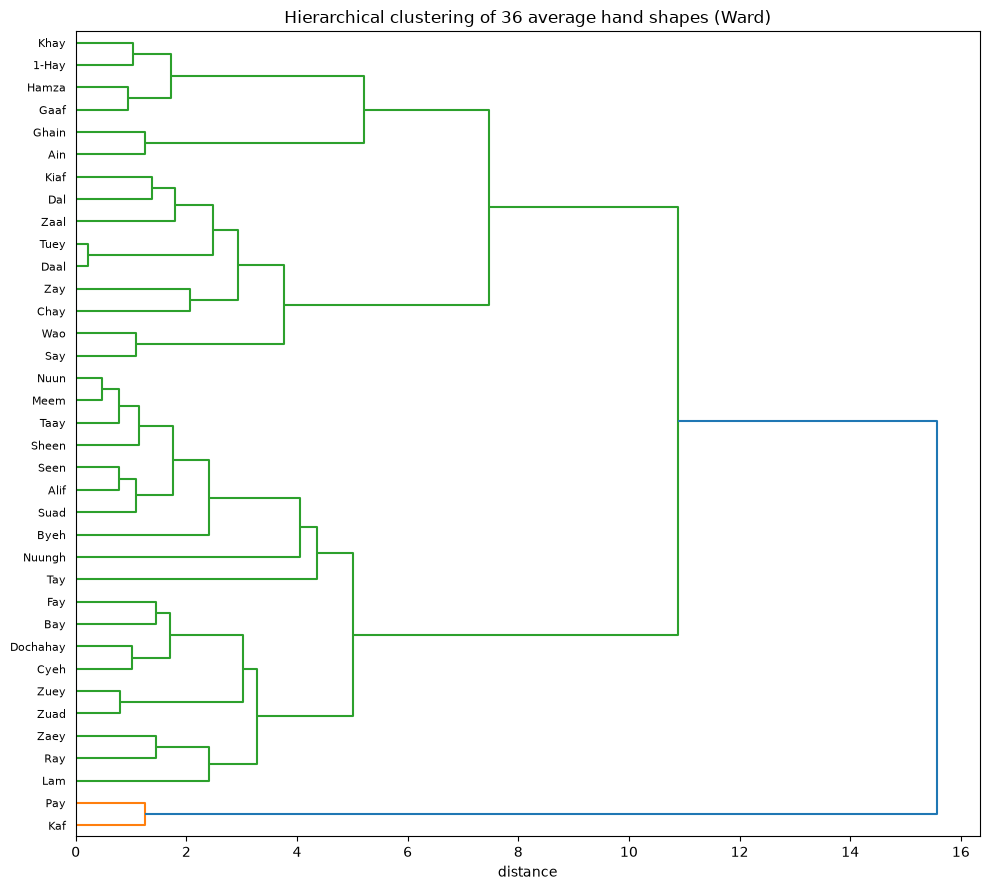

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
train = pd.read_csv(ROOT / "data/processed/train.csv")
feat_cols = [f"f{i}" for i in range(63)]

means = train.groupby("label")[feat_cols].mean()      # 36 harf x 63 numbers
print(means.shape)

Z = linkage(means.to_numpy(dtype=np.float64), method="ward")

fig, ax = plt.subplots(figsize=(10, 9))
dendrogram(Z, labels=means.index.to_list(), orientation="right", ax=ax)
ax.set_title("Hierarchical clustering of 36 average hand shapes (Ward)")
ax.set_xlabel("distance")
plt.tight_layout()
(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports/figures/07_dendrogram.png", dpi=150)
plt.show()

In [2]:
D = squareform(pdist(means.to_numpy(dtype=np.float64)))          # 36x36 doori
names = means.index.to_list()

iu = np.triu_indices(len(names), k=1)
pairs = pd.DataFrame({"a": np.array(names)[iu[0]],
                      "b": np.array(names)[iu[1]],
                      "dist": D[iu]})
pairs = pairs.sort_values("dist").reset_index(drop=True)
pairs["rank"] = pairs.index + 1

print("Sabse qareeb 10 jodiyan:")
print(pairs.head(10).round(3).to_string(index=False))

conf_pairs = [("Tuey", "Daal"), ("Ain", "Ghain"), ("Zuad", "Zuey"), ("Ray", "Zaal")]
print("\nConfusion wali jodiyon ki rank (630 jodiyon mein se):")
for a, b in conf_pairs:
    r = pairs[((pairs.a == a) & (pairs.b == b)) | ((pairs.a == b) & (pairs.b == a))]
    print(f"{a:6s}-{b:6s} rank {int(r['rank'].iloc[0]):3d} / {len(pairs)}   dist {r['dist'].iloc[0]:.3f}")

Sabse qareeb 10 jodiyan:
   a     b  dist  rank
Daal  Tuey 0.215     1
Meem  Nuun 0.481     2
Nuun  Taay 0.629     3
Alif  Seen 0.780     4
Meem  Taay 0.806     5
Zuad  Zuey 0.809     6
Seen  Taay 0.864     7
Alif  Suad 0.898     8
Seen Sheen 0.901     9
Meem  Seen 0.904    10

Confusion wali jodiyon ki rank (630 jodiyon mein se):
Tuey  -Daal   rank   1 / 630   dist 0.215
Ain   -Ghain  rank  26 / 630   dist 1.248
Zuad  -Zuey   rank   6 / 630   dist 0.809
Ray   -Zaal   rank 100 / 630   dist 2.135


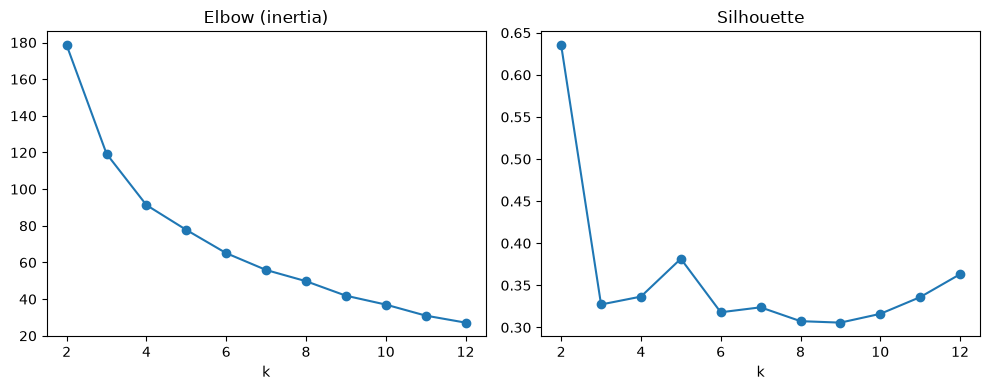

 k  inertia  silhouette
 2   178.53       0.635
 3   119.27       0.327
 4    91.31       0.337
 5    77.76       0.382
 6    65.09       0.318
 7    55.90       0.324
 8    49.78       0.307
 9    41.88       0.306
10    37.03       0.316
11    31.02       0.336
12    27.19       0.363


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pairs.to_csv(ROOT / "results/advanced_cluster_pairs.csv", index=False)   # report ke numbers is CSV se aayenge

Xm = means.to_numpy(dtype=np.float64)
ks = list(range(2, 13))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xm)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xm, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-");     ax[1].set_title("Silhouette");      ax[1].set_xlabel("k")
plt.tight_layout()
fig.savefig(ROOT / "reports/figures/08_kmeans_elbow_silhouette.png", dpi=150)
plt.show()

print(pd.DataFrame({"k": ks, "inertia": np.round(inertia, 2),
                    "silhouette": np.round(sil, 3)}).to_string(index=False))

In [4]:
pd.DataFrame({"k": ks, "inertia": np.round(inertia, 2),
              "silhouette": np.round(sil, 3)}).to_csv(ROOT / "results/advanced_kmeans_k.csv", index=False)

for k in (2, 5):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xm)
    print(f"\nk={k}")
    for c in range(k):
        members = [n for n, l in zip(names, km.labels_) if l == c]
        print(f"  cluster {c} ({len(members)}): " + ", ".join(members))


k=2
  cluster 0 (2): Kaf, Pay
  cluster 1 (34): 1-Hay, Ain, Alif, Bay, Byeh, Chay, Cyeh, Daal, Dal, Dochahay, Fay, Gaaf, Ghain, Hamza, Khay, Kiaf, Lam, Meem, Nuun, Nuungh, Ray, Say, Seen, Sheen, Suad, Taay, Tay, Tuey, Wao, Zaal, Zaey, Zay, Zuad, Zuey

k=5
  cluster 0 (2): Ain, Ghain
  cluster 1 (19): Alif, Bay, Byeh, Cyeh, Dochahay, Fay, Lam, Meem, Nuun, Nuungh, Ray, Seen, Sheen, Suad, Taay, Tay, Zaey, Zuad, Zuey
  cluster 2 (2): Kaf, Pay
  cluster 3 (4): 1-Hay, Gaaf, Hamza, Khay
  cluster 4 (9): Chay, Daal, Dal, Kiaf, Say, Tuey, Wao, Zaal, Zay
